here we are solving the issue of sending sending both and than we get the correct answer 

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv

from langchain.chat_models import init_chat_model
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition


load_dotenv(override=True)

tavily_tool = TavilySearch(max_results=2)

@tool
def multiply(a: int, b: int) -> int:
    """Multiply a and b.

    Args:
        a: first int
        b: second int
    """
    return a * b

tools = [tavily_tool, multiply]

llm = init_chat_model("google_genai:gemini-3.5-flash-lite")
llm_with_tools = llm.bind_tools(tools)

In [2]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

def tool_calling_llm(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition,
)
builder.add_edge("tools", "tool_calling_llm")  # <--- Loops back to the LLM!

graph = builder.compile()

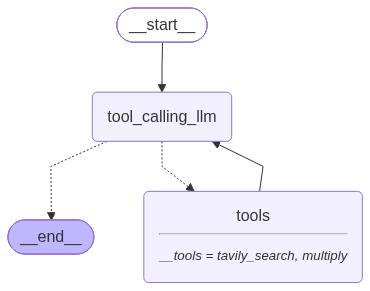

In [3]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_ascii())

In [4]:
response = graph.invoke(
    {"messages": "What is the recent ai news and then please multiply 5 by 2"}
)

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news and then please multiply 5 by 2
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_6001481461178930721)
 Call ID: call_6001481461178930721
  Args:
    query: latest artificial intelligence news 2026
  multiply (call_6001481461178931376)
 Call ID: call_6001481461178931376
  Args:
    b: 2
    a: 5
================================= Tool Message =================================
Name: tavily_search

{"query": "latest artificial intelligence news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://news.microsoft.com/source/features/ai/whats-next-in-ai-7-trends-to-watch-in-2026", "title": "What’s next in AI: 7 trends to watch in 2026", "content": "“The most effective AI infrastructure will pack computing power more densely across distributed networks,” Russinovich says. Next